In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [64]:
# 1. Loading Data
data_dir = Path("../../data")

print(f"Loading data from: {data_dir.resolve()}...")
bureau = pd.read_csv(data_dir / "bureau.csv")
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])

print(f"Loaded {len(bureau):,} bureau records and {len(app):,} applicant records.")




Loading data from: /Users/jobanpreetsingh/PycharmProjects/Loan Credit Risk Engine/data...
Loaded 1,716,428 bureau records and 307,511 applicant records.


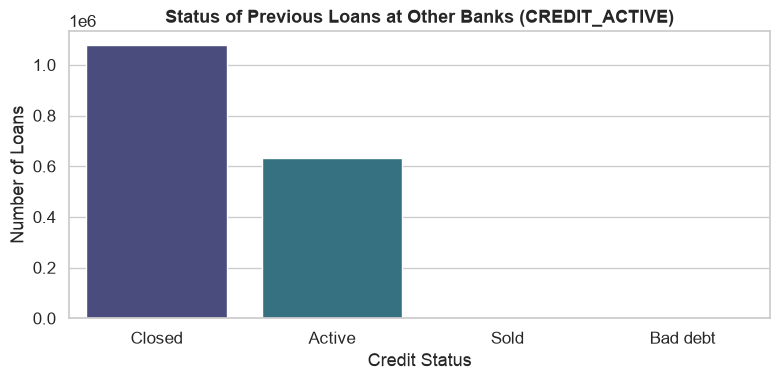

In [65]:
# 2. Plot Raw Credit Statuses at Other Banks
plt.figure(figsize=(8, 4))
sns.countplot(
    data=bureau,
    x="CREDIT_ACTIVE",
    hue="CREDIT_ACTIVE",
    palette="viridis",
    legend=False
)
plt.title("Status of Previous Loans at Other Banks (CREDIT_ACTIVE)", fontsize=13, fontweight="bold")
plt.xlabel("Credit Status")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()




In [66]:
# 3. Aggregate Bureau Data to 1 Row per Applicant
print("\nAggregating bureau records per applicant...")
bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    TOTAL_LOANS=("SK_ID_BUREAU", "count"),
    TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    MAX_DAYS_OVERDUE=("CREDIT_DAY_OVERDUE", "max")
).reset_index()

# Count active loans specifically
active = bureau[bureau["CREDIT_ACTIVE"] == "Active"].groupby("SK_ID_CURR")["SK_ID_BUREAU"].count().rename("ACTIVE_LOANS")
bureau_agg = bureau_agg.merge(active, on="SK_ID_CURR", how="left").fillna(0)

# Merge with applicant target to see repayment outcomes
merged = app.merge(bureau_agg, on="SK_ID_CURR", how="inner")
print(f"Successfully matched with {len(merged):,} applicants.")




Aggregating bureau records per applicant...
Successfully matched with 263,491 applicants.


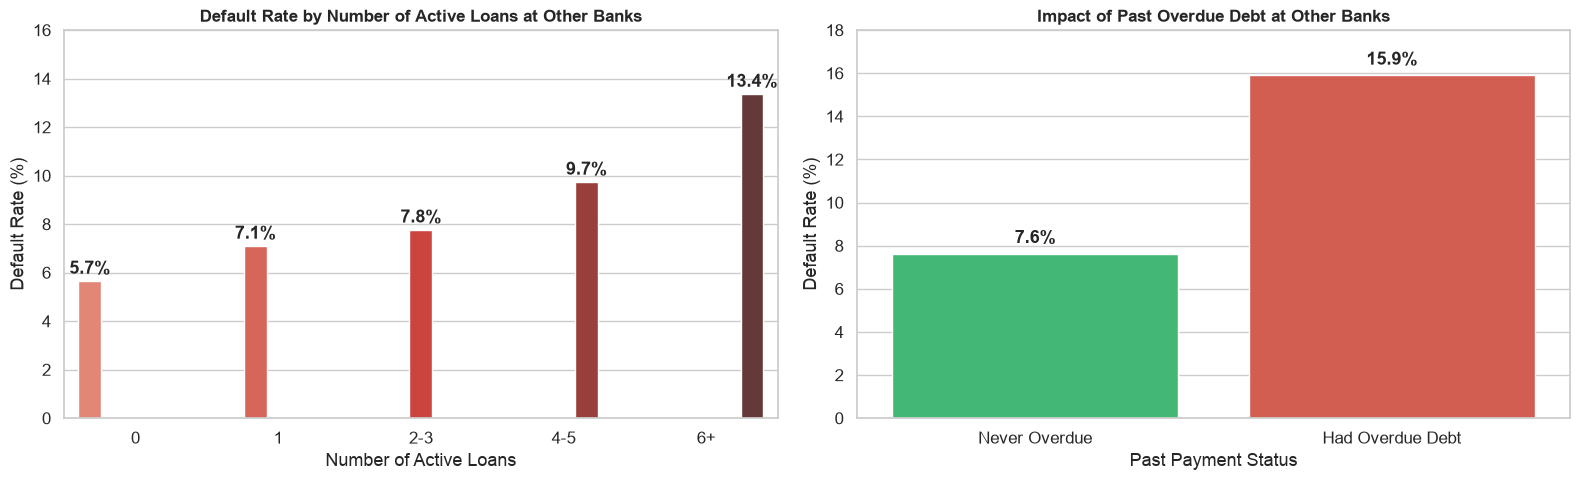

In [67]:
# 4. Side-by-Side Visualizations (Active Loans & Past Overdue)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# ─── Panel 1: Active Loans vs Default Rate ───
merged["ACTIVE_LOANS_BIN"] = pd.cut(
    merged["ACTIVE_LOANS"],
    bins=[-1, 0, 1, 3, 5, 20],
    labels=["0", "1", "2-3", "4-5", "6+"]
)
default_by_active = merged.groupby("ACTIVE_LOANS_BIN", observed=False)["TARGET"].mean() * 100

sns.barplot(
    x=default_by_active.index,
    y=default_by_active.values,
    hue=default_by_active.index,
    palette="Reds_d",
    legend=False,
    ax=ax1
)
ax1.set_title("Default Rate by Number of Active Loans at Other Banks", fontsize=12, fontweight="bold")
ax1.set_xlabel("Number of Active Loans")
ax1.set_ylabel("Default Rate (%)")
ax1.set_ylim(0, 16)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.3), ha="center", fontweight="bold")

# ─── Panel 2: Past Overdue Debt vs Default Rate ───
merged["HAS_PAST_OVERDUE"] = (merged["MAX_DAYS_OVERDUE"] > 0).astype(int)
default_by_overdue = merged.groupby("HAS_PAST_OVERDUE")["TARGET"].mean() * 100
overdue_labels = ["Never Overdue", "Had Overdue Debt"]

sns.barplot(
    x=overdue_labels,
    y=default_by_overdue.values,
    hue=overdue_labels,
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=ax2
)
ax2.set_title("Impact of Past Overdue Debt at Other Banks", fontsize=12, fontweight="bold")
ax2.set_xlabel("Past Payment Status")
ax2.set_ylabel("Default Rate (%)")
ax2.set_ylim(0, 18)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.5), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

